# PZ data challenge: results across all task sets

This notebook puts the results of the four task-set notebooks (`pz_challenge_taskset{1..4}_e2e.ipynb`) side by side. It covers all 16 configurations: 4 task sets × 2 sims × 2 depths. It reads the trained ensembles (the subtask 2 `.pkl` model files) those notebooks wrote to `OUT_DIR` (`outputs/znn` from scratch, `outputs/znn_pretrained_popcosmos` with pre-training, set by `PRETRAINING`; plus the method version `RUN` as a suffix) and trains nothing. All p(z)s are predicted here from those models with the current `znn` code, so the p(z) representation is the one `znn` produces now (a Gaussian with the mean and std of the predictions), whatever the run wrote as its own estimate files.

- **Part A, held-out scores** (the subtask 2 model files): each `.pkl` is reloaded and run on the same held-out split the task-set notebook used (`train_test_split` with `VAL_FRAC` and `SEED`). The results are scored with the challenge metrics and tiers. Predictions use the same photometric resampling as the submission (`N_SAMPLES` draws).
- **Part B, comparison with a baseline run**: Part A's held-out scores next to those of an earlier run, read from its held-out cache.
- **Part C, test-set p(z)** (optional, only with `PREDICT_TEST = True`): each model is run on its test file, as for the subtask 1 submission. The test redshifts are hidden, so this part only shows the predictions, i.e. the implied n(z) and the p(z) widths, set against the training redshift distribution.

The held-out and test-set predictions are cached in `CACHE_DIR`, outside `OUT_DIR` so they stay out of the submission tarball. Delete the cache to recompute, e.g. after changing how `znn` builds the p(z).

Run this from the repo root with the `qp` conda env as the kernel.

Plot conventions: **colour = depth** (blue 10yr, orange 1yr) and **line style = sim** (solid Cardinal, dashed Flagship).

## Configuration

In [1]:
import znn  # run from the repo root so this picks up the local source

TASKSETS = [1, 2, 3, 4]
SIMS = ["cardinal", "flagship"]
SCENARIOS = ["1yr", "10yr"]
TASKSET_NAMES = {
    1: "1: representative",
    2: "2: spec-selected",
    3: "3: spec + COSMOS",
    4: "4: spec + COSMOS, blended",
}

DATA_DIR = "../pz_data_challenge/scripts/public"  # as in the task-set notebooks
# Which run to read; must match the task-set notebooks: "popcosmos" (the pre-training shipped with znn) or None (from scratch). Each choice
# writes to its own directory, so runs with and without pre-training never overwrite each other.
PRETRAINING = "popcosmos"
# Method version, appended to OUT_DIR so runs of different versions never overwrite each other ("" for none):
# "noisytrain" (each member trained in full on its own noise realization) or "basefinetune" (a base model
# fine-tuned on each realization), see ENSEMBLE_TRAINING in the task-set notebooks; the p(z)s are predicted here
RUN = "noisytrain"
OUT_DIR = ("outputs/znn" if PRETRAINING is None else f"outputs/znn_pretrained_{PRETRAINING}") + (f"_{RUN}" if RUN else "")  # the submission files written by the task-set notebooks
CACHE_DIR = f"{OUT_DIR}_predictions"  # held-out (part A) and test-set (part C) predictions
# Part C, at the end: predict every model's test set (as for the subtask 1 file) and show the implied n(z). It
# takes about as long as the held-out predictions, so it only runs when True
PREDICT_TEST = False
PLOT_DIR = "plots"  # figures are saved here, prefixed with the run name so runs never overwrite each other

# the held-out split: must match the task-set notebooks
VAL_FRAC = 0.2
SEED = 42
# prediction: photometric noise draws per object (converged by 50 on Cardinal Y1) and their seed
N_SAMPLES = 50
NOISE_SEED = 42

I0000 00:00:1793213897.964679   10680 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793213897.968019   10680 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793213898.304145   10680 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793213899.873071   10680 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

In [2]:
import itertools
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import qp
from qp.metrics.pit import PIT
from sklearn.model_selection import train_test_split

from pz_data_challenge import scoring

os.makedirs(CACHE_DIR, exist_ok=True)
os.makedirs(PLOT_DIR, exist_ok=True)

CONFIGS = list(itertools.product(TASKSETS, SIMS, SCENARIOS))
ZGRID = np.linspace(0, 3, 601)  # where p(z)s and the stacked n(z) are evaluated
COLORS = {"10yr": "#2a78d6", "1yr": "#eb6834"}
LINESTYLES = {"cardinal": "-", "flagship": "--"}
TRAIN_COLOR = "0.6"


def style(sim, scenario):
    return dict(color=COLORS[scenario], ls=LINESTYLES[sim], lw=1.5, label=f"{sim} {scenario}")


def save(fig, name):
    fig.savefig(os.path.join(PLOT_DIR, f"{os.path.basename(OUT_DIR)}_{name}.pdf"), bbox_inches="tight")


def path(kind, taskset, sim, scenario):
    if kind in ("training", "test"):
        return os.path.join(DATA_DIR, f"pz_challenge_taskset_{taskset}_{sim}_{kind}_{scenario}.hdf5")
    return os.path.join(OUT_DIR, f"pz_challenge_taskset_{taskset}_{sim}_{kind}_{scenario}.pkl")


missing = [p for c in CONFIGS if not os.path.exists(p := path("pz_model", *c))]
assert not missing, f"missing model files: {missing}"

## Reference redshifts

These are the same labels as in the task-set notebooks. Task sets 1 and 2 use `redshift`. Task sets 3 and 4 use `redshift` for spectroscopically selected objects and `redshift_manyband` for COSMOS-only objects, so scores on the COSMOS-only objects include the label noise.

In [3]:
SPEC_SURVEYS = ["DEEP2_LSST", "DESI_BGS", "DESI_ELG_LOP", "DESI_LRG", "VVDSf02", "zCOSMOS"]


def reference_redshifts(train):
    # Reference redshift per training object, and the held-out subsets to score (masks over train).
    z_spec = train["redshift"].to_numpy()
    if "COSMOS" not in train:  # task sets 1 and 2
        subsets = {"all": np.ones(len(train), dtype=bool)}
        if (train["mag_i_lsst"] < 23.5).all():
            return z_spec, subsets  # task set 1
        return z_spec, subsets | {"i > 23": train["mag_i_lsst"].to_numpy() > 23}  # task set 2

    is_spec = train[[c for c in SPEC_SURVEYS if c in train]].astype(bool).any(axis=1).to_numpy()
    is_cosmos_only = train["COSMOS"].astype(bool).to_numpy() & ~is_spec
    z_ref = np.where(is_cosmos_only, train["redshift_manyband"].to_numpy(), z_spec)
    assert np.isfinite(z_ref).all()
    return z_ref, {"all": np.ones(len(train), dtype=bool), "spec": is_spec, "COSMOS-only": is_cosmos_only}

# Part A: held-out scores

For each configuration the model file is reloaded and run on the held-out 20% of the training file. The model was trained on the other 80%, the same split as in the task-set notebooks. Each held-out set is scored on all of its objects and on the subsets the task-set notebook reported: task set 2 has `i > 23`, the faintest objects available, and task sets 3 and 4 have spec-selected and COSMOS-only.

Only task set 1 has a held-out set that is representative of its test set. For the other task sets these scores are **optimistic** for the test set.

In [4]:
def heldout_predictions(taskset, sim, scenario):
    # Held-out reference z, i-mag, subset masks, zmode, the p(z) mean and std, and the ensemble's p(z) (a qp
    # ensemble) under "pz". Cached in CACHE_DIR: the arrays in <stem>.npz, the p(z) in <stem>.hdf5.
    stem = os.path.join(CACHE_DIR, f"taskset_{taskset}_{sim}_{scenario}_pz")
    if os.path.exists(f"{stem}.npz") and os.path.exists(f"{stem}.hdf5"):
        return dict(np.load(f"{stem}.npz")) | {"pz": qp.read(f"{stem}.hdf5")}

    train = znn.read_catalog(path("training", taskset, sim, scenario))
    z_ref, subsets = reference_redshifts(train)
    _, idx_val = train_test_split(np.arange(len(train)), test_size=VAL_FRAC, random_state=SEED)
    val = train.iloc[idx_val]

    trained_models, features = znn.load_ensemble_file(path("pz_model", taskset, sim, scenario))
    errors = {col: f"{col}_err" for col, _ in features["bands"].values()}
    pz = znn.predict_from_catalog(
        trained_models, val, **features, errors=errors, n_samples=N_SAMPLES, rng=np.random.default_rng(NOISE_SEED)
    )
    out = {
        "z_ref": z_ref[idx_val],
        "mag_i": val["mag_i_lsst"].to_numpy(),
        "zmode": np.squeeze(pz.ancil["zmode"]),
        "mean": np.squeeze(pz.mean()),
        "std": np.squeeze(pz.std()),
        **{f"subset:{name}": mask[idx_val] for name, mask in subsets.items()},
    }
    np.savez(f"{stem}.npz", **out)
    pz.write_to(f"{stem}.hdf5")
    return out | {"pz": pz}


heldout = {}
for c in CONFIGS:
    print("held-out predictions:", *c)
    heldout[c] = heldout_predictions(*c)

held-out predictions: 1 cardinal 1yr
held-out predictions: 1 cardinal 10yr
held-out predictions: 1 flagship 1yr


E0000 00:00:1793213900.761959   10680 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
I0000 00:00:1793213901.287732   11730 service.cc:153] XLA service 0x7ac538037560 initialized for platform Host (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793213901.287753   11730 service.cc:161]   StreamExecutor [0]: Host, Default Version (Driver: 0.0.0; Runtime: 0.0.0; Toolkit: 0.0.0; DNN: 0.0.0)
I0000 00:00:1793213901.312784   11730 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1793213901.539349   11730 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


held-out predictions: 1 flagship 10yr
held-out predictions: 2 cardinal 1yr
held-out predictions: 2 cardinal 10yr
held-out predictions: 2 flagship 1yr
held-out predictions: 2 flagship 10yr
held-out predictions: 3 cardinal 1yr


/home/jaimerz/Documents/UCL/mlpz_cnn_deepset/znn/data.py:159: RuntimeWarning: invalid value encountered in subtract
  mags_normed = mags - mag_i[None, :]  # normalize by i-band mag, per band, before binning


held-out predictions: 3 cardinal 10yr
held-out predictions: 3 flagship 1yr


...

held-out predictions: 3 flagship 10yr
held-out predictions: 4 cardinal 1yr


/home/jaimerz/Documents/UCL/mlpz_cnn_deepset/znn/data.py:159: RuntimeWarning: invalid value encountered in subtract
  mags_normed = mags - mag_i[None, :]  # normalize by i-band mag, per band, before binning


held-out predictions: 4 cardinal 10yr
held-out predictions: 4 flagship 1yr


/home/jaimerz/Documents/UCL/mlpz_cnn_deepset/znn/data.py:159: RuntimeWarning: invalid value encountered in subtract
  mags_normed = mags - mag_i[None, :]  # normalize by i-band mag, per band, before binning


held-out predictions: 4 flagship 10yr


In [5]:
def challenge_metrics(z_ref, zmode, pz):
    # The challenge's seven scored metrics, computed as in the task-set notebooks.
    dz = (zmode - z_ref) / (1 + z_ref)
    bias, _, scatter, _, abs_outlier_rate = znn.get_biweight_mean_sigma_outlier(dz)
    pit = PIT(pz, z_ref)
    return {
        "mean": bias,
        "std": scatter,
        "abs_outlier_rate": abs_outlier_rate,
        "ks": pit.evaluate_PIT_KS().statistic,
        "CvM": pit.evaluate_PIT_CvM().statistic,
        "ksamp": pit.evaluate_PIT_anderson_ksamp().statistic,
        # qp derives this from a spline fit to the PIT quantiles and it breaks down (negative or huge values)
        # when PIT piles up at 0 or 1; the challenge evaluator uses the same call, so it is what gets scored
        "outlier": pit.evaluate_PIT_outlier_rate(),
        # what it is meant to measure, computed directly (not scored)
        "pit_outlier_direct": np.mean((pit.pit_samps < 0.0001) | (pit.pit_samps > 0.9999)),
    }, pit.pit_samps


def tier_points(values):
    return {name: sum(lo <= float(values[name]) <= hi for lo, hi in ranges) for name, ranges in scoring.metric_dict.items()}


results, pits = {}, {}
for c, h in heldout.items():
    for key in [k for k in h if k.startswith("subset:")]:
        m = h[key]
        results[(*c, key.removeprefix("subset:"))], pits[(*c, key.removeprefix("subset:"))] = challenge_metrics(
            h["z_ref"][m], h["zmode"][m], h["pz"][np.flatnonzero(m)]
        )

table = pd.DataFrame(results).T[list(scoring.metric_dict) + ["pit_outlier_direct"]]
table.index.names = ["taskset", "sim", "scenario", "subset"]
points = pd.DataFrame({k: tier_points(v) for k, v in results.items()}).T
points.index.names = table.index.names
points["total"] = points.sum(axis=1)
N_MAX = sum(len(r) for r in scoring.metric_dict.values())
table.round(4)

/home/jaimerz/Documents/UCL/mlpz_cnn_deepset/.venv/lib/python3.12/site-packages/qp/metrics/array_metrics.py:27: UserWarning: Parameter `variant` has been introduced to replace `midrank`; `midrank` will be removed in SciPy 1.19.0. Specify `variant` to silence this warning. Note that the returned object will no longer be unpackable as a tuple, and `critical_values` will be omitted.
  return stats.anderson_ksamp([p_random_variables, q_random_variables], **kwargs)
/home/jaimerz/Documents/UCL/mlpz_cnn_deepset/.venv/lib/python3.12/site-packages/qp/metrics/array_metrics.py:27: UserWarning: p-value floored: true value smaller than 0.001. Consider specifying `method` (e.g. `method=stats.PermutationMethod()`.)
  return stats.anderson_ksamp([p_random_variables, q_random_variables], **kwargs)


mean     std  abs_outlier_rate  \
taskset sim      scenario subset                                          
1       cardinal 1yr      all          0.0007  0.0187            0.0014   
                 10yr     all          0.0009  0.0121            0.0001   
        flagship 1yr      all         -0.0000  0.0205            0.0011   
                 10yr     all         -0.0003  0.0121            0.0000   
2       cardinal 1yr      all          0.0017  0.0242            0.0083   
                          i > 23      -0.0018  0.0390            0.0207   
                 10yr     all          0.0007  0.0146            0.0006   
                          i > 23      -0.0017  0.0190            0.0011   
        flagship 1yr      all         -0.0004  0.0278            0.0069   
                          i > 23      -0.0048  0.0412            0.0154   
                 10yr     all         -0.0004  0.0148            0.0001   
                          i > 23      -0.0026  0.0186            0.0003   
3       cardinal 1yr      all          0.0058  0.0311            0.0516   
                          spec         0.0059  0.0197            0.0183   
                          COSMOS-only  0.0082  0.0917            0.1140   
                 10yr     all          0.0049  0.0213            0.0275   
                          spec         0.0045  0.0153            0.0017   
                          COSMOS-only  0.0073  0.0493            0.0724   
        flagship 1yr      all          0.0049  0.0415            0.0874   
                          spec         0.0057  0.0229            0.0034   
                          COSMOS-only  0.0086  0.1076            0.1641   
                 10yr     all          0.0011  0.0288            0.0432   
                          spec         0.0002  0.0160            0.0004   
                          COSMOS-only  0.0043  0.0530            0.0786   
4       cardinal 1yr      all          0.0059  0.0357            0.0522   
                          spec         0.0069  0.0232            0.0211   
                          COSMOS-only  0.0023  0.0891            0.1124   
                 10yr     all          0.0018  0.0203            0.0277   
                          spec         0.0018  0.0145            0.0063   
                          COSMOS-only  0.0026  0.0483            0.0667   
        flagship 1yr      all         -0.0042  0.0418            0.0860   
                          spec        -0.0040  0.0227            0.0049   
                          COSMOS-only -0.0008  0.1033            0.1578   
                 10yr     all          0.0007  0.0305            0.0496   
                          spec         0.0010  0.0176            0.0023   
                          COSMOS-only  0.0010  0.0572            0.0891   

                                            CvM       outlier      ks  \
taskset sim      scenario subset                                        
1       cardinal 1yr      all           70.6496  6.090000e-02  0.0943   
                 10yr     all           71.9750  5.670000e-02  0.0964   
        flagship 1yr      all           83.2870  4.210000e-02  0.0924   
                 10yr     all          105.9593  2.580000e-02  0.1068   
2       cardinal 1yr      all           80.2131  1.790000e-02  0.1000   
                          i > 23        13.3922  1.170000e-02  0.0743   
                 10yr     all           70.7395  2.030000e-02  0.0932   
                          i > 23        18.9280  3.700000e-03  0.0848   
        flagship 1yr      all           75.4229  2.430000e-02  0.0901   
                          i > 23        26.9435  1.010000e-02  0.0922   
                 10yr     all          111.3675  5.800000e-03  0.1079   
                          i > 23        39.3440  1.540000e-02  0.1128   
3       cardinal 1yr      all          250.3081  4.100000e-02  0.1774   
                          spec         198.3816  2.130000e-02  0.1894   
                      

### Points against the challenge tiers

There is one point per nested range a metric falls inside, so at most 3 per metric and 21 per configuration (`pz_data_challenge.scoring.metric_dict`). The table uses the `all` held-out subset.

A 0 under `outlier` is usually not a real failure. qp computes that metric from a spline fit to the PIT quantiles, which breaks down (negative or huge values) when PIT piles up at 0 or 1, so compare with `pit_outlier_direct` in the table above. The challenge evaluator makes the same call, so these are the points it would award.

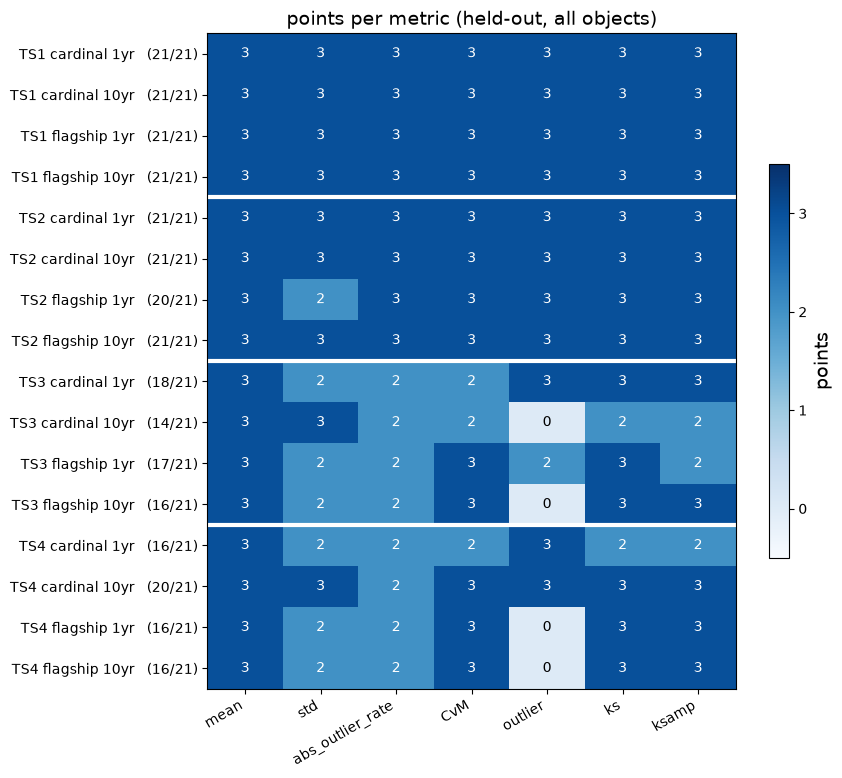

total points per task set (sum over its 4 configurations, held-out all):
taskset
1    84
2    83
3    65
4    68 
(out of 84 each)


In [6]:
pts_all = points.xs("all", level="subset")
labels = [f"TS{t} {s} {y}" for t, s, y in pts_all.index]
metrics = list(scoring.metric_dict)

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(pts_all[metrics].to_numpy(), cmap="Blues", vmin=-0.5, vmax=3.5, aspect="auto")
for (i, j), v in np.ndenumerate(pts_all[metrics].to_numpy()):
    ax.text(j, i, int(v), ha="center", va="center", fontsize=10, color="white" if v >= 2 else "black")
ax.set_xticks(range(len(metrics)), metrics, rotation=30, ha="right")
ax.set_yticks(range(len(labels)), [f"{l}   ({t}/{N_MAX})" for l, t in zip(labels, pts_all["total"])])
for y in (3.5, 7.5, 11.5):
    ax.axhline(y, color="white", lw=3)
ax.set_title("points per metric (held-out, all objects)")
fig.colorbar(im, ax=ax, ticks=[0, 1, 2, 3], shrink=0.6, label="points")
fig.tight_layout()
save(fig, "points")
plt.show()

print("total points per task set (sum over its 4 configurations, held-out all):")
print(pts_all["total"].groupby(level="taskset").sum().to_string(), f"\n(out of {4 * N_MAX} each)")

### Subsets

These are the same metrics on the task-set-specific subsets. Task set 2's `i > 23` subset is the closest proxy for its faint test set. In task sets 3 and 4, `COSMOS-only` is the faint, test-like part, scored against noisy many-band labels.

In [7]:
sub = table.drop(index="all", level="subset")
sub_points = points.drop(index="all", level="subset")["total"].rename(f"points (/{N_MAX})")
pd.concat([sub, sub_points], axis=1).round(4)

mean     std  abs_outlier_rate  \
taskset sim      scenario subset                                          
2       cardinal 1yr      i > 23      -0.0018  0.0390            0.0207   
                 10yr     i > 23      -0.0017  0.0190            0.0011   
        flagship 1yr      i > 23      -0.0048  0.0412            0.0154   
                 10yr     i > 23      -0.0026  0.0186            0.0003   
3       cardinal 1yr      spec         0.0059  0.0197            0.0183   
                          COSMOS-only  0.0082  0.0917            0.1140   
                 10yr     spec         0.0045  0.0153            0.0017   
                          COSMOS-only  0.0073  0.0493            0.0724   
        flagship 1yr      spec         0.0057  0.0229            0.0034   
                          COSMOS-only  0.0086  0.1076            0.1641   
                 10yr     spec         0.0002  0.0160            0.0004   
                          COSMOS-only  0.0043  0.0530            0.0786   
4       cardinal 1yr      spec         0.0069  0.0232            0.0211   
                          COSMOS-only  0.0023  0.0891            0.1124   
                 10yr     spec         0.0018  0.0145            0.0063   
                          COSMOS-only  0.0026  0.0483            0.0667   
        flagship 1yr      spec        -0.0040  0.0227            0.0049   
                          COSMOS-only -0.0008  0.1033            0.1578   
                 10yr     spec         0.0010  0.0176            0.0023   
                          COSMOS-only  0.0010  0.0572            0.0891   

                                            CvM       outlier      ks  \
taskset sim      scenario subset                                        
2       cardinal 1yr      i > 23        13.3922  1.170000e-02  0.0743   
                 10yr     i > 23        18.9280  3.700000e-03  0.0848   
        flagship 1yr      i > 23        26.9435  1.010000e-02  0.0922   
                 10yr     i > 23        39.3440  1.540000e-02  0.1128   
3       cardinal 1yr      spec         198.3816  2.130000e-02  0.1894   
                          COSMOS-only   75.0972  1.728894e+02  0.1657   
                 10yr     spec         267.8457  1.071000e-01  0.2210   
                          COSMOS-only   93.9117  1.095777e+15  0.1831   
        flagship 1yr      spec         111.8526  4.920000e-02  0.1639   
                          COSMOS-only  141.5378 -1.493788e+02  0.1885   
                 10yr     spec          40.4817 -7.070000e-02  0.1186   
                          COSMOS-only  124.9479 -1.608651e+03  0.1751   
4       cardinal 1yr      spec         277.7062  4.190000e-02  0.2254   
                          COSMOS-only   73.4389  2.415302e+02  0.1576   
                 10yr     spec          80.4717  3.080000e-02  0.1280   
                          COSMOS-only   49.0611 -5.683107e+09  0.1328   
        flagship 1yr      spec          63.9438  4.140000e-02  0.1324   
                          COSMOS-only  112.8551 -3.477865e+03  0.1512   
                 10yr     spec          76.5702  7.540000e-02  0.1502   
                          COSMOS-only  114.7792 -1.874696e+03  0.1680   

                                           ksamp  pit_outlier_direct  \
taskset sim      scenario subset                                       
2       cardinal 1yr      i > 23         75.0561              0.0140   
                 10yr     i > 23         94.2855              0.0093   
        flagship 1yr      i > 23        128.4742              0.0124   
                 10yr     i > 23        180.1873              0.0155   
3       cardinal 1yr      spec          703.9691              0.0213   
                          COSMOS-only   370.0212              0.0805   
                 10yr     spec         1016.2577              0.0457   
                          COSMOS-only   433.4472              0.0976   
        flagship 1yr      spec          428.3134              0

### PIT

PIT histograms on the `all` held-out subset. A flat histogram means the p(z) is calibrated. A U shape means it is too narrow, and a hump means it is too wide.

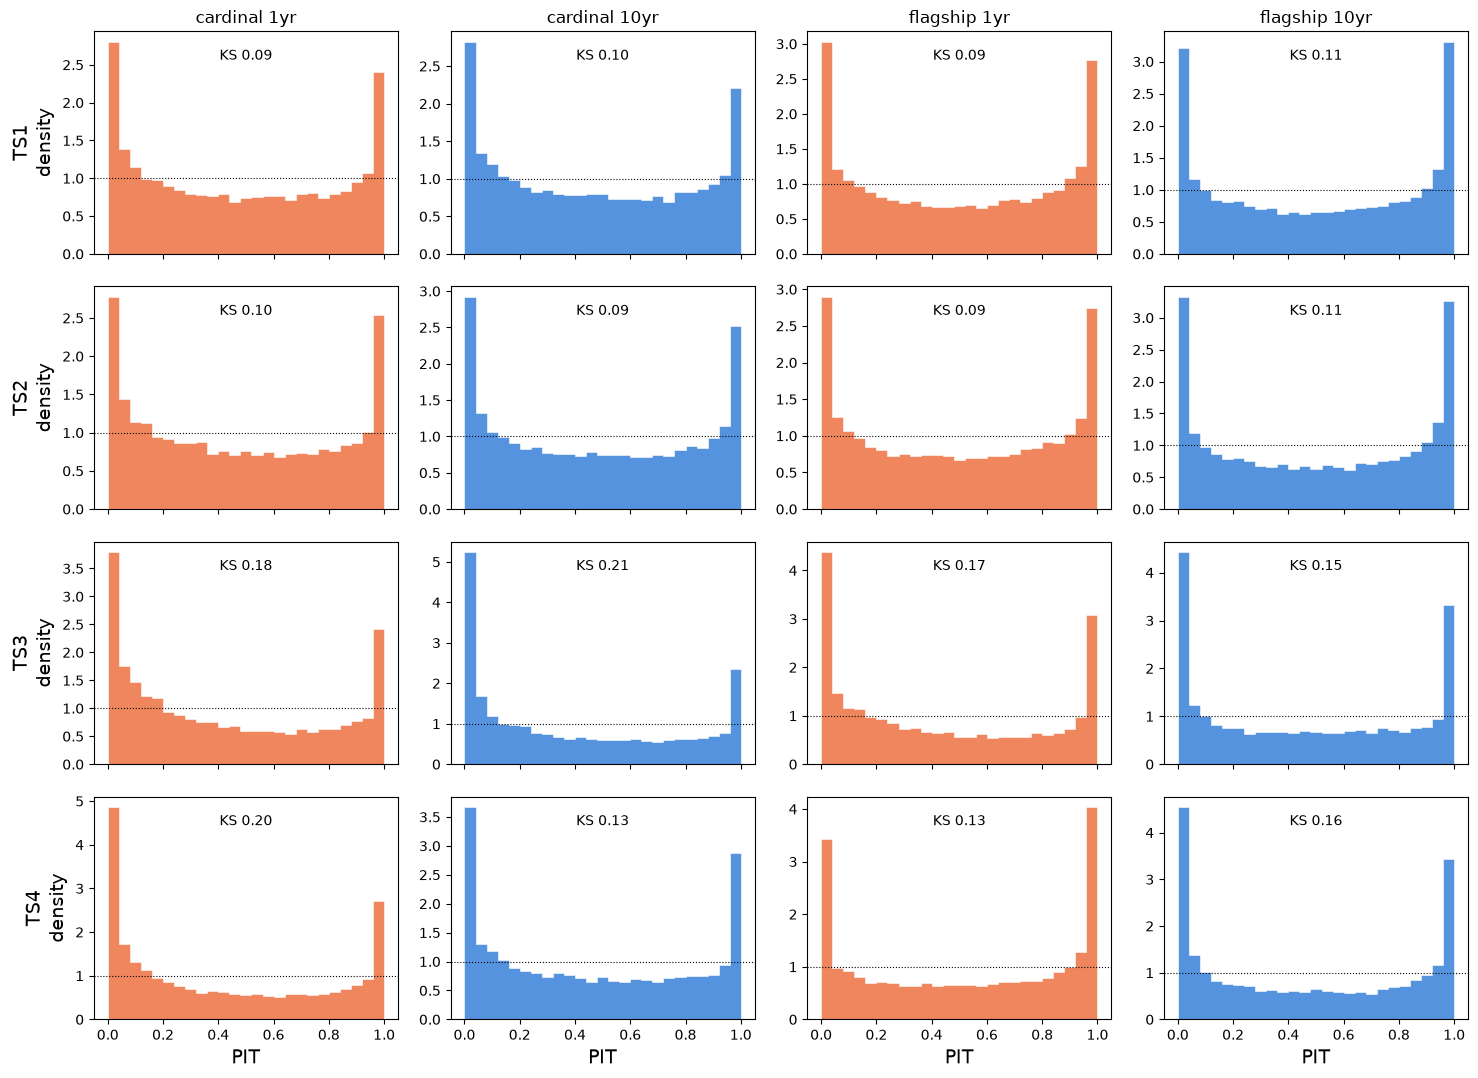

In [8]:
pit_bins = np.linspace(0, 1, 26)
fig, axes = plt.subplots(4, 4, figsize=(15, 11), sharex=True)
for row, taskset in enumerate(TASKSETS):
    for col, (sim, scenario) in enumerate(itertools.product(SIMS, SCENARIOS)):
        ax = axes[row, col]
        ax.hist(pits[(taskset, sim, scenario, "all")], pit_bins, density=True, color=COLORS[scenario],
                histtype="stepfilled", alpha=0.8, ec="white", lw=0.5)
        ax.axhline(1, color="k", lw=0.8, ls=":")
        ks = table.loc[(taskset, sim, scenario, "all"), "ks"]
        ax.text(0.5, 0.92, f"KS {ks:.2f}", transform=ax.transAxes, ha="center", va="top", fontsize=10)
        if row == 0:
            ax.set_title(f"{sim} {scenario}", fontsize=12)
        if col == 0:
            ax.set_ylabel(f"TS{taskset}\ndensity")
        if row == 3:
            ax.set_xlabel("PIT")
fig.tight_layout()
save(fig, "pit")
plt.show()

### Point estimates

`zmode` against the reference redshift on the `all` held-out subset (log-density 2D histogram). The dashed lines mark |Δz|/(1+z) = 0.2, the outlier threshold.

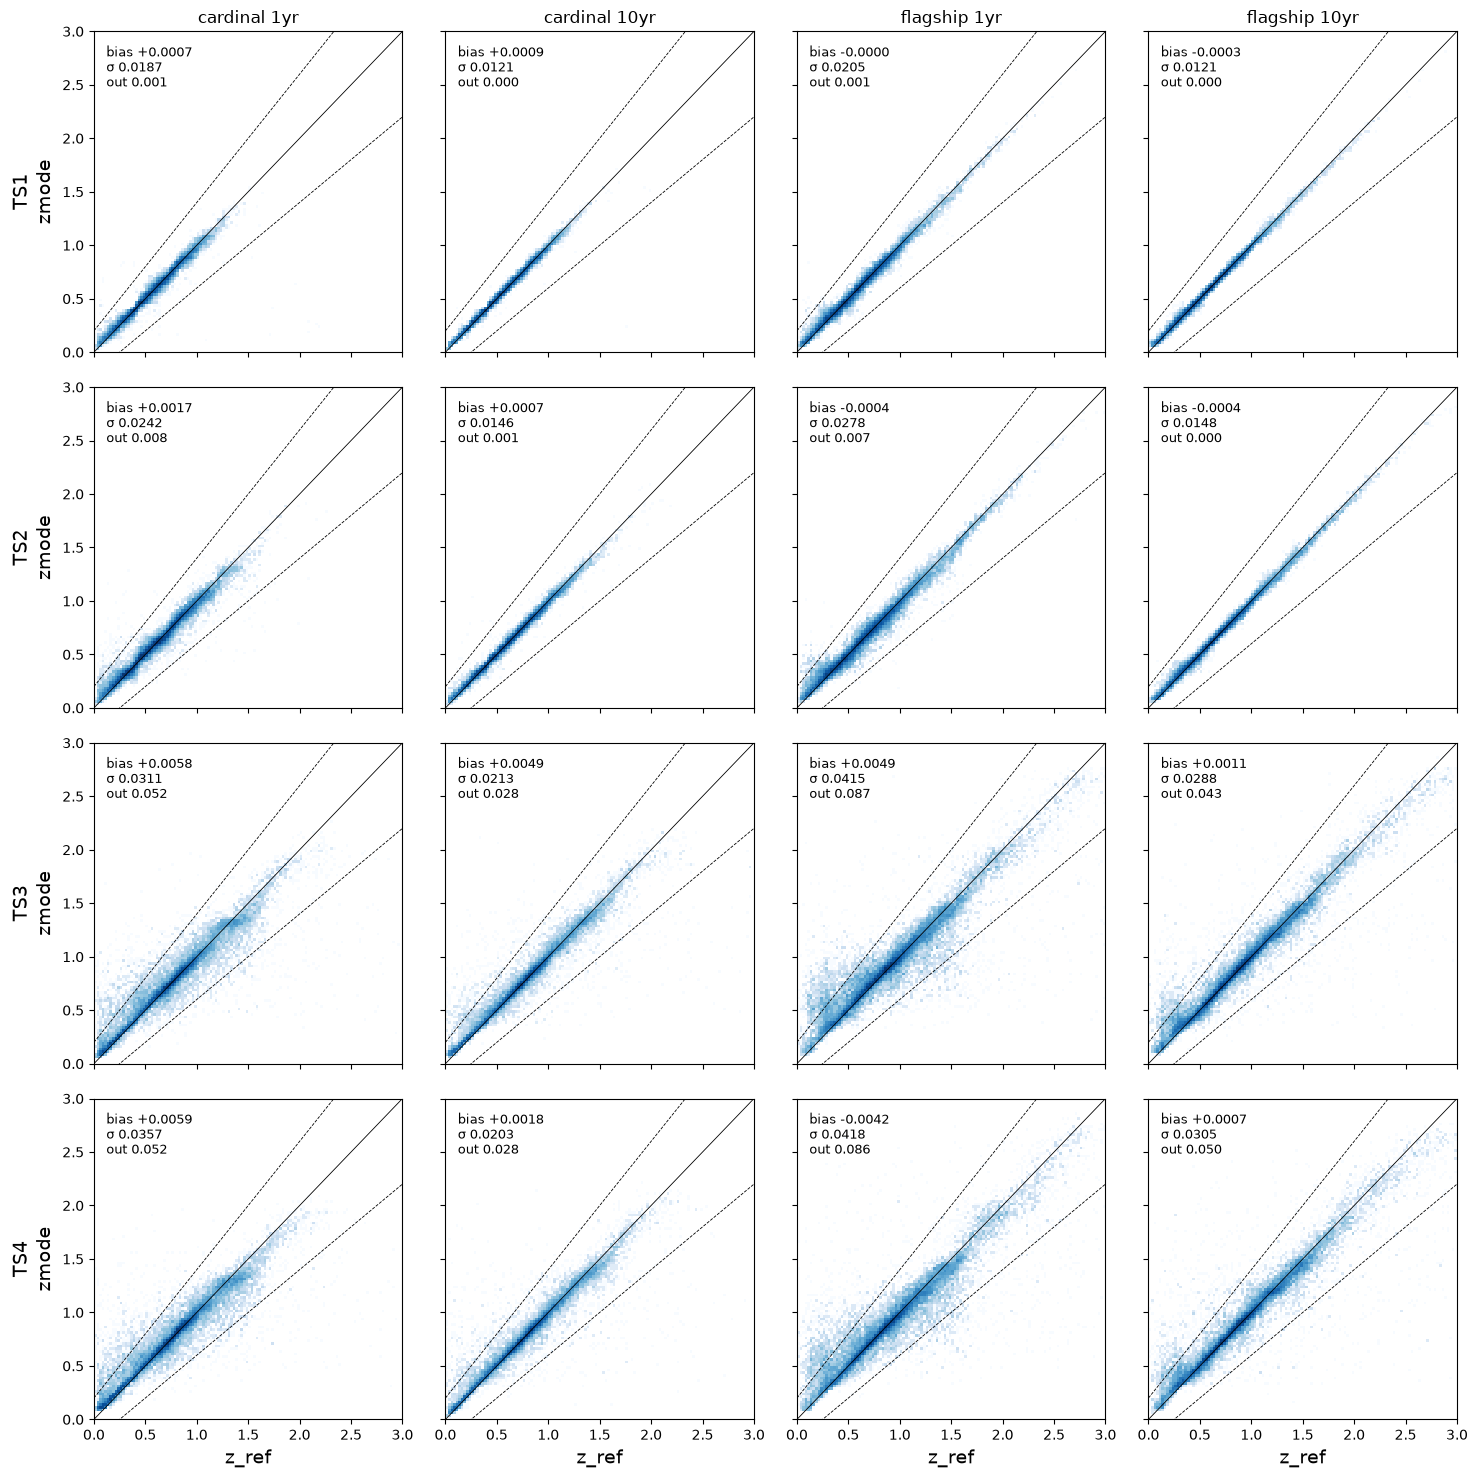

In [9]:
from matplotlib.colors import LogNorm

zb = np.linspace(0, 3, 121)
fig, axes = plt.subplots(4, 4, figsize=(15, 15), sharex=True, sharey=True)
for row, taskset in enumerate(TASKSETS):
    for col, (sim, scenario) in enumerate(itertools.product(SIMS, SCENARIOS)):
        ax = axes[row, col]
        h = heldout[(taskset, sim, scenario)]
        ax.hist2d(h["z_ref"], h["zmode"], bins=[zb, zb], cmap="Blues", norm=LogNorm(), rasterized=True)
        ax.plot(zb, zb, color="k", lw=0.6)
        for sgn in (-1, 1):
            ax.plot(zb, zb + sgn * 0.2 * (1 + zb), color="k", lw=0.6, ls="--")
        v = table.loc[(taskset, sim, scenario, "all")]
        ax.text(0.04, 0.96, f"bias {v['mean']:+.4f}\nσ {v['std']:.4f}\nout {v['abs_outlier_rate']:.3f}",
                transform=ax.transAxes, va="top", fontsize=9)
        ax.set_xlim(0, 3)
        ax.set_ylim(0, 3)
        if row == 0:
            ax.set_title(f"{sim} {scenario}", fontsize=12)
        if col == 0:
            ax.set_ylabel(f"TS{taskset}\nzmode")
        if row == 3:
            ax.set_xlabel("z_ref")
fig.tight_layout()
save(fig, "zphot_vs_zref")
plt.show()

# Part B: comparison with a baseline run

Part A's held-out scores next to those of an earlier run, read from that run's held-out cache. The baseline is the version before `RUN = "noisytrain"` (in which the members share one data cut and start from the same pre-trained popcosmos member, and train on their own noise realizations): every member trained on the catalogue photometry as given, on its own K-fold cut of the training objects, starting from its own pre-trained popcosmos member, and a Gaussian p(z) with the mean and std of the `N_SAMPLES` × members predictions. Its cache holds `z_ref`, `mag_i`, `mean`, `std` and the subset masks per configuration. Configurations missing from the cache are predicted from the baseline's model files (`BASELINE_OUT_DIR`) and added to it. It is scored here exactly as that version scored it, with the Gaussian mean as the point estimate.

Both runs use the same held-out split (`VAL_FRAC`, `SEED`), so they are scored on the same objects; this is checked.

In [10]:
# The baseline run: its OUT_DIR, with its model files, and its held-out cache (<BASELINE_OUT_DIR>_heldout:
# z_ref, mag_i, mean, std and the subset masks per configuration). A configuration missing from the cache
# (e.g. on a machine where the baseline was never scored) is predicted from its model file and added to it.
BASELINE_OUT_DIR = "outputs/znn_pretrained_popcosmos"
BASELINE_LABEL = "baseline"
NEW_LABEL = RUN or "new"
BASELINE_CACHE = f"{BASELINE_OUT_DIR}_heldout"
os.makedirs(BASELINE_CACHE, exist_ok=True)


def baseline_heldout(taskset, sim, scenario):
    cache = os.path.join(BASELINE_CACHE, f"taskset_{taskset}_{sim}_{scenario}.npz")
    if os.path.exists(cache):
        return dict(np.load(cache))
    model_file = os.path.join(BASELINE_OUT_DIR, f"pz_challenge_taskset_{taskset}_{sim}_pz_model_{scenario}.pkl")
    assert os.path.exists(model_file), f"no baseline held-out cache or model file for {(taskset, sim, scenario)}: {model_file}"
    train = znn.read_catalog(path("training", taskset, sim, scenario))
    z_ref, subsets = reference_redshifts(train)
    _, idx_val = train_test_split(np.arange(len(train)), test_size=VAL_FRAC, random_state=SEED)
    val = train.iloc[idx_val]
    trained_models, features = znn.load_ensemble_file(model_file)
    errors = {col: f"{col}_err" for col, _ in features["bands"].values()}
    pz = znn.predict_from_catalog(
        trained_models, val, **features, errors=errors, n_samples=N_SAMPLES, rng=np.random.default_rng(NOISE_SEED))
    out = {
        "z_ref": z_ref[idx_val],
        "mag_i": val["mag_i_lsst"].to_numpy(),
        "mean": np.squeeze(pz.mean()),
        "std": np.squeeze(pz.std()),
        **{f"subset:{name}": mask[idx_val] for name, mask in subsets.items()},
    }
    np.savez(cache, **out)
    return out


base_results, base_pits = {}, {}
for c in CONFIGS:
    b = baseline_heldout(*c)
    assert np.array_equal(b["z_ref"], heldout[c]["z_ref"]), f"{c}: the baseline was scored on different held-out objects"
    for key in [k for k in b if k.startswith("subset:")]:
        m = b[key]
        pz = qp.Ensemble(qp.stats.norm, data={"loc": b["mean"][m, None], "scale": b["std"][m, None]})
        base_results[(*c, key.removeprefix("subset:"))], base_pits[(*c, key.removeprefix("subset:"))] = challenge_metrics(
            b["z_ref"][m], b["mean"][m], pz
        )

base_table = pd.DataFrame(base_results).T[table.columns]
base_table.index.names = table.index.names
base_points = pd.DataFrame({k: tier_points(v) for k, v in base_results.items()}).T
base_points.index.names = table.index.names
base_points["total"] = base_points.sum(axis=1)

# metrics side by side on the "all" subset, baseline then new for each metric
comparison = pd.concat({BASELINE_LABEL: base_table, NEW_LABEL: table}, axis=1).xs("all", level="subset")
comparison = comparison.swaplevel(axis=1)[[(m, r) for m in table.columns for r in (BASELINE_LABEL, NEW_LABEL)]]
comparison.round(4)

/home/jaimerz/Documents/UCL/mlpz_cnn_deepset/.venv/lib/python3.12/site-packages/qp/metrics/array_metrics.py:27: UserWarning: Parameter `variant` has been introduced to replace `midrank`; `midrank` will be removed in SciPy 1.19.0. Specify `variant` to silence this warning. Note that the returned object will no longer be unpackable as a tuple, and `critical_values` will be omitted.
  return stats.anderson_ksamp([p_random_variables, q_random_variables], **kwargs)
/home/jaimerz/Documents/UCL/mlpz_cnn_deepset/.venv/lib/python3.12/site-packages/qp/metrics/array_metrics.py:27: UserWarning: p-value floored: true value smaller than 0.001. Consider specifying `method` (e.g. `method=stats.PermutationMethod()`.)
  return stats.anderson_ksamp([p_random_variables, q_random_variables], **kwargs)


mean                 std             \
                          baseline noisytrain baseline noisytrain   
taskset sim      scenario                                           
1       cardinal 1yr        0.0018     0.0007   0.0178     0.0187   
                 10yr       0.0007     0.0009   0.0113     0.0121   
        flagship 1yr        0.0004    -0.0000   0.0199     0.0205   
                 10yr      -0.0002    -0.0003   0.0117     0.0121   
2       cardinal 1yr        0.0038     0.0017   0.0233     0.0242   
                 10yr       0.0015     0.0007   0.0138     0.0146   
        flagship 1yr        0.0004    -0.0004   0.0265     0.0278   
                 10yr       0.0002    -0.0004   0.0146     0.0148   
3       cardinal 1yr        0.0049     0.0058   0.0274     0.0311   
                 10yr       0.0034     0.0049   0.0187     0.0213   
        flagship 1yr        0.0006     0.0049   0.0390     0.0415   
                 10yr       0.0036     0.0011   0.0271     0.0288   
4       cardinal 1yr        0.0050     0.0059   0.0311     0.0357   
                 10yr       0.0023     0.0018   0.0191     0.0203   
        flagship 1yr        0.0029    -0.0042   0.0410     0.0418   
                 10yr       0.0005     0.0007   0.0283     0.0305   

                          abs_outlier_rate                  CvM             \
                                  baseline noisytrain  baseline noisytrain   
taskset sim      scenario                                                    
1       cardinal 1yr                0.0016     0.0014   60.0568    70.6496   
                 10yr               0.0002     0.0001   33.1502    71.9750   
        flagship 1yr                0.0012     0.0011   49.9918    83.2870   
                 10yr               0.0000     0.0000   67.6786   105.9593   
2       cardinal 1yr                0.0088     0.0083   94.0360    80.2131   
                 10yr               0.0005     0.0006   52.6316    70.7395   
        flagship 1yr                0.0070     0.0069   50.3089    75.4229   
                 10yr               0.0001     0.0001   73.5690   111.3675   
3       cardinal 1yr                0.0530     0.0516  197.6412   250.3081   
                 10yr               0.0264     0.0275  141.7956   349.8245   
        flagship 1yr                0.0848     0.0874  118.8407   232.7586   
                 10yr               0.0438     0.0432  280.6862   154.7601   
4       cardinal 1yr                0.0544     0.0522  219.5655   310.4588   
                 10yr               0.0290     0.0277  132.9337   126.9104   
        flagship 1yr                0.0872     0.0860  163.6175   141.9930   
                 10yr               0.0506     0.0496  131.8563   190.2397   

                           outlier                  ks                 ksamp  \
                          baseline noisytrain baseline noisytrain   baseline   
taskset sim      scenario                                                      
1       cardinal 1yr        0.0104     0.0609   0.0872     0.0943   274.2693   
                 10yr       0.0025     0.0567   0.0664     0.0964   176.0174   
        flagship 1yr        0.0093     0.0421   0.0766     0.0924   287.0153   
                 10yr       0.0300     0.0258   0.0848     0.1068   395.2444   
2       cardinal 1yr        0.0101     0.0179   0.1001     0.1000   358.4737   
                 10yr       0.0033     0.0203   0.0780     0.0932   240.3856   
        flagship 1yr        0.0181     0.0243   0.0774     0.0901   290.3315   
                 10yr       0.0375     0.0058   0.0933     0.1079   422.3434   
3       cardinal 1yr        0.0600     0.0410   0.1518     0.1774   755.2102   
                 10yr     -52.2018  -218.1899   0.1196     0.2059   593.5728   
        flagship 1yr       -0.0730     0.2059   0.1206     0.1668   635.6084   
                 10yr     -11.1572     1.1149   0.1920     0.1481  1277.2156   
4       cardinal 1yr        0.0823 

In [11]:
# challenge points, per configuration and summed per task set ("all" subset)
pts = pd.DataFrame(
    {
        BASELINE_LABEL: base_points.xs("all", level="subset")["total"],
        NEW_LABEL: points.xs("all", level="subset")["total"],
    }
)
pts["change"] = pts[NEW_LABEL] - pts[BASELINE_LABEL]
print(f"points per configuration (out of {N_MAX}):")
display(pts)
print(f"points per task set (out of {4 * N_MAX}):")
display(pts.groupby(level="taskset").sum())

# every subset, as differences new - baseline: lower is better for |mean|, std, abs_outlier_rate, ks, CvM, ksamp
diff = table[list(scoring.metric_dict)] - base_table[list(scoring.metric_dict)]
diff["|mean|"] = table["mean"].abs() - base_table["mean"].abs()
diff["points"] = points["total"] - base_points["total"]
diff.round(4)

points per configuration (out of 21):


baseline  noisytrain  change
taskset sim      scenario                              
1       cardinal 1yr             21          21       0
                 10yr            21          21       0
        flagship 1yr             21          21       0
                 10yr            21          21       0
2       cardinal 1yr             21          21       0
                 10yr            21          21       0
        flagship 1yr             20          20       0
                 10yr            21          21       0
3       cardinal 1yr             19          18      -1
                 10yr            17          14      -3
        flagship 1yr             16          17       1
                 10yr            14          16       2
4       cardinal 1yr             19          16      -3
                 10yr            20          20       0
        flagship 1yr             19          16      -3
                 10yr            17          16      -1

points per task set (out of 84):


,baseline,noisytrain,change
taskset,,,
1,84,84,0
2,83,83,0
3,66,65,-1
4,75,68,-7


mean     std  abs_outlier_rate  \
taskset sim      scenario subset                                          
1       cardinal 1yr      all         -0.0011  0.0009           -0.0002   
                 10yr     all          0.0003  0.0007           -0.0002   
        flagship 1yr      all         -0.0005  0.0006           -0.0000   
                 10yr     all         -0.0001  0.0003            0.0000   
2       cardinal 1yr      all         -0.0021  0.0009           -0.0005   
                          i > 23      -0.0053  0.0005           -0.0014   
                 10yr     all         -0.0009  0.0009            0.0001   
                          i > 23      -0.0018  0.0004            0.0000   
        flagship 1yr      all         -0.0008  0.0012           -0.0001   
                          i > 23      -0.0016  0.0006           -0.0010   
                 10yr     all         -0.0006  0.0002            0.0000   
                          i > 23      -0.0007  0.0001            0.0000   
3       cardinal 1yr      all          0.0008  0.0037           -0.0014   
                          spec         0.0010  0.0016            0.0010   
                          COSMOS-only -0.0031  0.0017           -0.0059   
                 10yr     all          0.0016  0.0026            0.0011   
                          spec         0.0015  0.0023            0.0005   
                          COSMOS-only -0.0002  0.0014            0.0022   
        flagship 1yr      all          0.0043  0.0025            0.0026   
                          spec         0.0055  0.0015           -0.0002   
                          COSMOS-only  0.0023  0.0078            0.0051   
                 10yr     all         -0.0025  0.0017           -0.0006   
                          spec        -0.0026  0.0011            0.0002   
                          COSMOS-only -0.0026  0.0015           -0.0012   
4       cardinal 1yr      all          0.0009  0.0045           -0.0021   
                          spec         0.0021  0.0029           -0.0014   
                          COSMOS-only -0.0072  0.0020           -0.0035   
                 10yr     all         -0.0005  0.0012           -0.0013   
                          spec        -0.0001  0.0011            0.0002   
                          COSMOS-only -0.0029  0.0007           -0.0040   
        flagship 1yr      all         -0.0070  0.0007           -0.0012   
                          spec        -0.0063  0.0004           -0.0001   
                          COSMOS-only -0.0096  0.0035           -0.0022   
                 10yr     all          0.0001  0.0022           -0.0010   
                          spec         0.0009  0.0020            0.0003   
                          COSMOS-only -0.0012  0.0017           -0.0021   

                                            CvM       outlier      ks  \
taskset sim      scenario subset                                        
1       cardinal 1yr      all           10.5928  5.060000e-02  0.0071   
                 10yr     all           38.8248  5.420000e-02  0.0300   
        flagship 1yr      all           33.2951  3.280000e-02  0.0158   
                 10yr     all           38.2807 -4.200000e-03  0.0220   
2       cardinal 1yr      all          -13.8229  7.700000e-03 -0.0001   
                          i > 23         4.5880  4.900000e-03  0.0153   
                 10yr     all           18.1079  1.690000e-02  0.0152   
                          i > 23        16.4496  2.600000e-03  0.0507   
        flagship 1yr      all           25.1140  6.200000e-03  0.0127   
                          i > 23        15.7215  2.000000e-03  0.0327   
                 10yr     all           37.7986 -3.170000e-02  0.0146   
                          i > 23        22.6004  1.310000e-02  0.0366   
3       cardinal 1yr      all           52.6669 -1.900000e-02  0.0257   
                          spec          51.1697  1.080000e-02  0.0309   
                      

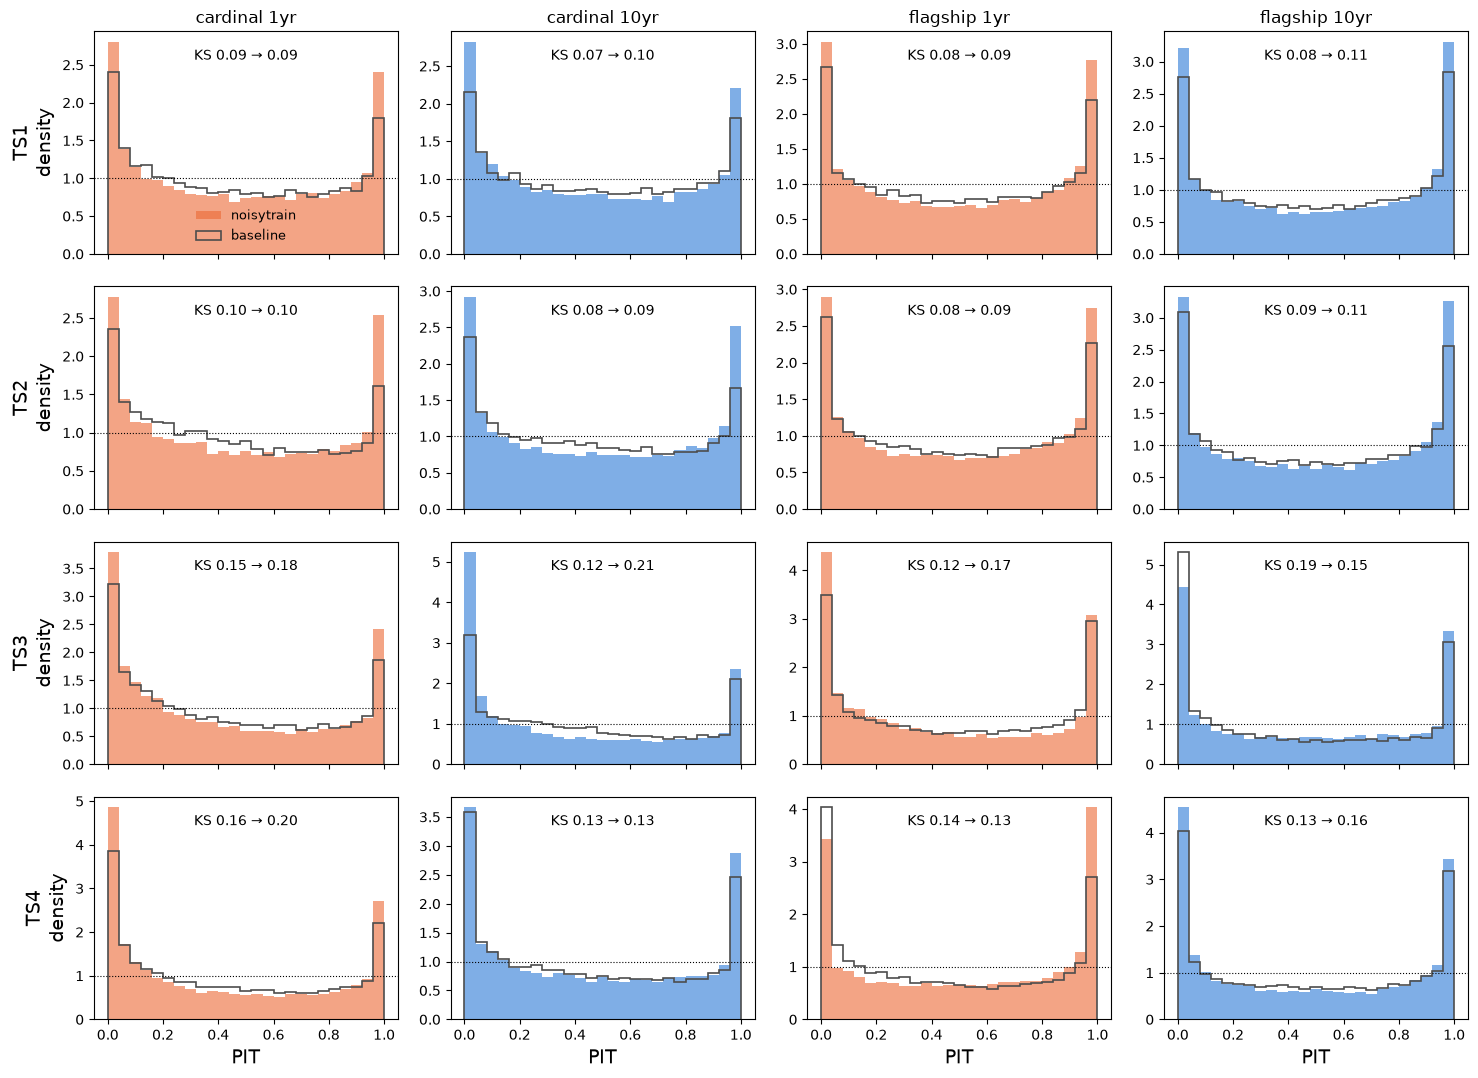

In [12]:
# PIT of the two runs on the "all" held-out subset: baseline outlined in grey, new filled
fig, axes = plt.subplots(4, 4, figsize=(15, 11), sharex=True)
for row, taskset in enumerate(TASKSETS):
    for col, (sim, scenario) in enumerate(itertools.product(SIMS, SCENARIOS)):
        ax = axes[row, col]
        key = (taskset, sim, scenario, "all")
        ax.hist(pits[key], pit_bins, density=True, color=COLORS[scenario], histtype="stepfilled", alpha=0.6,
                label=NEW_LABEL)
        ax.hist(base_pits[key], pit_bins, density=True, color="0.3", histtype="step", lw=1.2, label=BASELINE_LABEL)
        ax.axhline(1, color="k", lw=0.8, ls=":")
        ax.text(0.5, 0.92, f"KS {base_table.loc[key, 'ks']:.2f} → {table.loc[key, 'ks']:.2f}", transform=ax.transAxes,
                ha="center", va="top", fontsize=10)
        if row == 0:
            ax.set_title(f"{sim} {scenario}", fontsize=12)
        if col == 0:
            ax.set_ylabel(f"TS{taskset}\ndensity")
        if row == 3:
            ax.set_xlabel("PIT")
axes[0, 0].legend(fontsize=9, frameon=False, loc="lower center")
fig.tight_layout()
save(fig, "pit_vs_baseline")
plt.show()

# Appendix: what the CNN sees

The model does not take the band magnitudes as a list. Each magnitude (minus the reference i band) is spread over wavelength with its filter curve, and the result is averaged into `n_bins` equal-width wavelength bins. This gives a continuous curve (channel 0 of `X`), which is shown here for a few held-out galaxies across redshift.

- **Left:** the encoding of the catalogue photometry, drawn through the `n_bins` bin centres as in `znn.visualize_the_data`. The shaded band is the 16–84% range over `N_DRAWS` photometric resamplings, i.e. the noise the ensemble sees in training and at prediction time. The filter curves are in the strip on top. Bins with no observed band are 0 (and have 0 in the coverage channel).
- **Right:** the predicted p(z) for that galaxy from Part A (built from all its predictions), with the reference redshift as a dashed line.

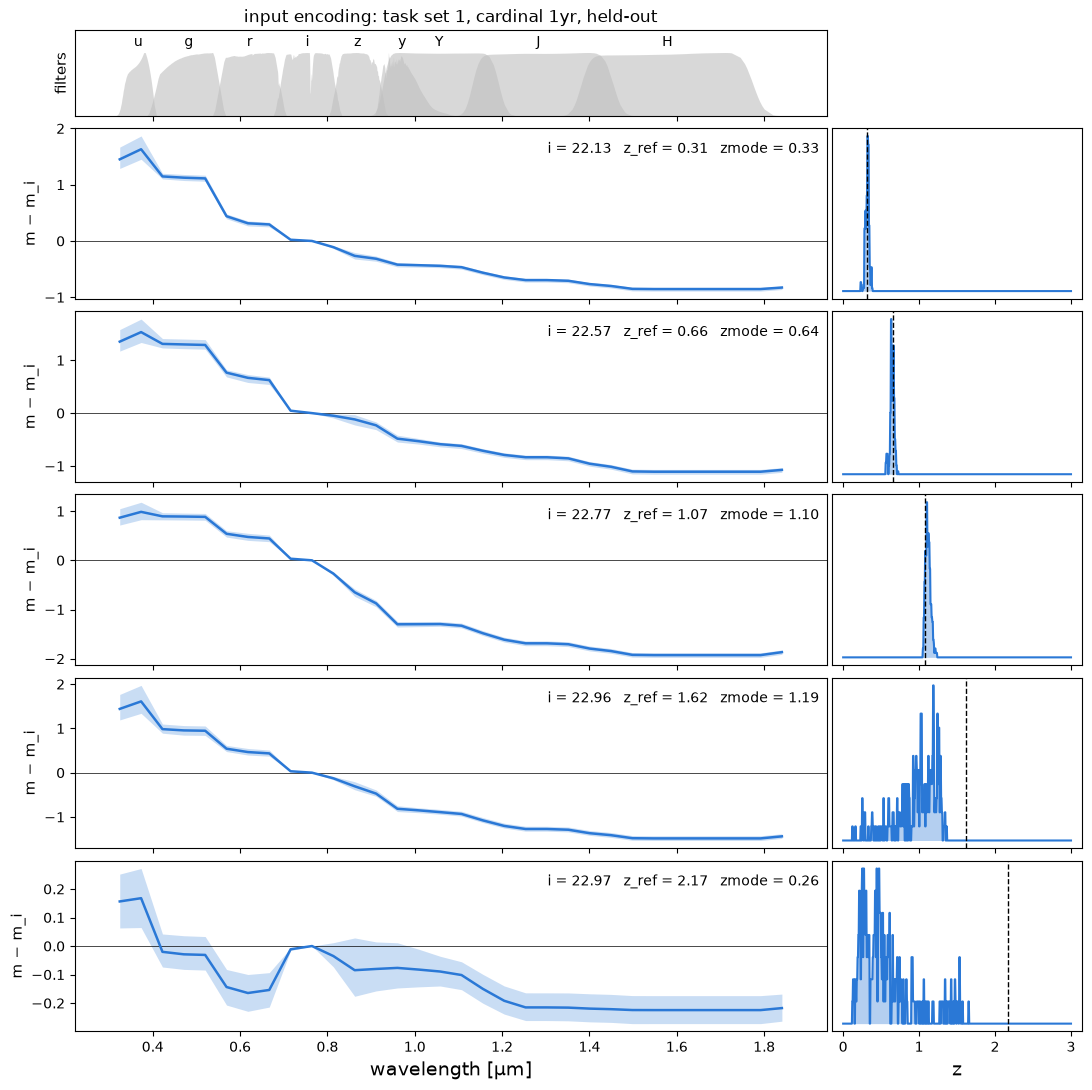

In [13]:
EXAMPLE = (1, "cardinal", "1yr")  # (task set, sim, depth); 1yr makes the photometric errors easier to see
Z_TARGETS = [0.3, 0.7, 1.1, 1.6, 2.2]  # one galaxy picked near each reference redshift
IMAG_RANGE = (22.0, 23.5)  # faint enough for the errors to show
N_DRAWS = 200
rng = np.random.default_rng(1)

train = znn.read_catalog(path("training", *EXAMPLE))
_, idx_val = train_test_split(np.arange(len(train)), test_size=VAL_FRAC, random_state=SEED)
h = heldout[EXAMPLE]
_, features = znn.load_ensemble_file(path("pz_model", *EXAMPLE))
bands, curves, cfg = features["bands"], features["filter_curves"], features["config"]
errors = {col: f"{col}_err" for col, _ in bands.values()}

in_mag = (h["mag_i"] > IMAG_RANGE[0]) & (h["mag_i"] < IMAG_RANGE[1])
picks = [rng.choice(np.flatnonzero(in_mag & (np.abs(h["z_ref"] - zt) < 0.05))) for zt in Z_TARGETS]
gal = train.iloc[idx_val[picks]]

# wavelength bin centres, as catalog_to_XY builds them
lambda_common = np.linspace(min(c[:, 0].min() for c in curves.values()), max(c[:, 0].max() for c in curves.values()), cfg["n_lambda"])
lam_bins, _ = znn.make_lambda_bins(lambda_common, cfg["n_bins"])
lam_eff = {b: np.sum(c[:, 0] * c[:, 1]) / np.sum(c[:, 1]) for b, c in curves.items()}

X_obs, _ = znn.catalog_to_XY(gal, **features)
enc_draws = [znn.catalog_to_XY(znn.resample_photometry(gal, errors, rng), **features)[0][..., 0] for _ in range(N_DRAWS)]
enc_lo, enc_hi = np.percentile(enc_draws, [16, 84], axis=0)

ENC = "#2a78d6"
um = 1e-4  # filter curves are in Angstrom
fig, axes = plt.subplots(
    len(picks) + 1, 2, figsize=(13, 2.3 * len(picks) + 1.5), sharex="col",
    gridspec_kw=dict(height_ratios=[0.5] + [1] * len(picks), width_ratios=[3, 1], hspace=0.08, wspace=0.01),
)
for b, c in curves.items():
    axes[0, 0].fill_between(c[:, 0] * um, c[:, 1] / c[:, 1].max(), color="0.75", alpha=0.6, lw=0)
    axes[0, 0].text(lam_eff[b] * um, 1.05, b, ha="center", va="bottom", fontsize=10)
axes[0, 0].set_ylim(0, 1.35)
axes[0, 0].set_yticks([])
axes[0, 0].set_ylabel("filters", fontsize=11)
axes[0, 1].axis("off")

for row, (k, j) in enumerate(zip(range(len(picks)), picks), start=1):
    ax = axes[row, 0]
    ax.axhline(0, color="k", lw=0.5)
    ax.fill_between(lam_bins * um, enc_lo[k], enc_hi[k], color=ENC, alpha=0.25, lw=0)
    ax.plot(lam_bins * um, X_obs[k, :, 0], color=ENC, lw=1.8)
    ax.set_ylabel("m − m_i", fontsize=11)
    ax.text(0.99, 0.92, f"i = {h['mag_i'][j]:.2f}   z_ref = {h['z_ref'][j]:.2f}   zmode = {h['zmode'][j]:.2f}",
            transform=ax.transAxes, ha="right", va="top", fontsize=10)

    ax = axes[row, 1]
    pdf = np.squeeze(h["pz"][[j]].pdf(ZGRID))
    ax.fill_between(ZGRID, pdf, color=ENC, alpha=0.35, lw=0)
    ax.plot(ZGRID, pdf, color=ENC, lw=1.5)
    ax.axvline(h["z_ref"][j], color="k", ls="--", lw=1)
    ax.set_yticks([])
axes[-1, 0].set_xlabel("wavelength [μm]")
axes[-1, 1].set_xlabel("z")
axes[0, 0].set_title(f"input encoding: task set {EXAMPLE[0]}, {EXAMPLE[1]} {EXAMPLE[2]}, held-out", fontsize=12)
save(fig, "encoding")
plt.show()

# Part C: test-set p(z)

Runs only with `PREDICT_TEST = True`.


Each model is run on its test file (`N_SAMPLES` noise draws, as for the submission), giving per-object Gaussian p(z)s with the mean and std of all `N_SAMPLES` × members predictions. They are cached in `CACHE_DIR`, and summarised by their `zmode` (the challenge's point estimate), mean and std, and matched to its test catalogue by `object_id` to pick up the i-band magnitude.

In [14]:
def test_predictions(taskset, sim, scenario):
    # The model's test-set p(z) (a qp ensemble), predicted as for the subtask 1 file. Cached in CACHE_DIR.
    cache = os.path.join(CACHE_DIR, f"test_taskset_{taskset}_{sim}_{scenario}_pz.hdf5")
    if os.path.exists(cache):
        return qp.read(cache)
    trained_models, features = znn.load_ensemble_file(path("pz_model", taskset, sim, scenario))
    test = znn.read_catalog(path("test", taskset, sim, scenario))
    errors = {col: f"{col}_err" for col, _ in features["bands"].values()}
    pz = znn.predict_from_catalog(
        trained_models, test, **features, errors=errors, n_samples=N_SAMPLES, rng=np.random.default_rng(NOISE_SEED),
        ids=test["object_id"].to_numpy(),
    )
    pz.write_to(cache)
    return pz


def read_estimate(taskset, sim, scenario):
    # Per-object summaries of the test-set p(z), and the stacked n(z) (mean p(z)) on ZGRID.
    pz = test_predictions(taskset, sim, scenario)
    est = pd.DataFrame(
        {
            "object_id": np.squeeze(pz.ancil["object_id"]),
            "zmode": np.squeeze(pz.ancil["zmode"]),
            "mean": np.squeeze(pz.mean()),
            "std": np.squeeze(pz.std()),
        }
    )
    test = znn.read_catalog(path("test", taskset, sim, scenario), columns=["object_id", "mag_i_lsst"])
    est = est.merge(test, on="object_id", how="left", validate="one_to_one")
    assert est["mag_i_lsst"].notna().all()
    return est, pz.pdf(ZGRID).mean(axis=0)


if PREDICT_TEST:
    estimates, stacked_nz, train_z = {}, {}, {}
    for c in CONFIGS:
        print("test-set predictions:", *c)
        estimates[c], stacked_nz[c] = read_estimate(*c)
        train = znn.read_catalog(path("training", *c))
        train_z[c], _ = reference_redshifts(train)

    summary = pd.DataFrame(
        {
            c: {
                "N test": len(e),
                "median zmode": e["zmode"].median(),
                "median σ": e["std"].median(),
                "median σ/(1+z)": (e["std"] / (1 + e["zmode"])).median(),
                "frac z < 0": (e["zmode"] < 0).mean(),
                "median i (test)": e["mag_i_lsst"].median(),
            }
            for c, e in estimates.items()
        }
    ).T
    summary.index.names = ["taskset", "sim", "scenario"]
    display(summary.round(4))


### Implied n(z) of the test set

The stacked test-set p(z) (the mean of the per-object p(z)s) against the training reference redshifts (grey, 10yr file). Task set 1 should agree with training. For task sets 2–4 the test set is fainter than the training set, so any difference between the two shows how far the model has to extrapolate.

In [15]:
if PREDICT_TEST:
    fig, axes = plt.subplots(2, 4, figsize=(16, 6.5), sharex=True, sharey=True)
    for col, taskset in enumerate(TASKSETS):
        for row, sim in enumerate(SIMS):
            ax = axes[row, col]
            ax.hist(train_z[(taskset, sim, "10yr")], bins=np.linspace(0, 3, 61), density=True,
                    histtype="stepfilled", color=TRAIN_COLOR, alpha=0.35, label="training z_ref")
            for scenario in SCENARIOS:
                ax.plot(ZGRID, stacked_nz[(taskset, sim, scenario)], **style(sim, scenario))
            ax.axvline(0, color="k", lw=0.5)
            if row == 0:
                ax.set_title(f"task set {TASKSET_NAMES[taskset]}", fontsize=12)
            if row == 1:
                ax.set_xlabel("z")
            if col == 0:
                ax.set_ylabel(f"{sim}\nn(z)")
            ax.legend(fontsize=9, frameon=False)
    fig.tight_layout()
    save(fig, "nz")
    plt.show()